<a href="https://colab.research.google.com/github/jcesaryanez-collab/agtech-ai-portfolio/blob/main/02_eficiencia_operativa_tractor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de Eficiencia Operativa: Massey Ferguson 6465

**Autor:** Julio Cesar Yañez Ramirez
**Fecha:** 21/11/2026
**Fuente de datos:** OECD Test 2433 – Nebraska Summary 696 (AGCO S.A.)

**Objetivo:** Analizar los datos del ensayo oficial del tractor para determinar su eficiencia de tracción, consumo de combustible y costo operativo en diferentes marchas. Este análisis ayuda a tomar decisiones sobre la marcha óptima para distintas labores agrícolas, minimizando el consumo y el desgaste.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configuración para que los gráficos se vean bien
plt.style.use('ggplot')

## 1. Carga de Datos

Extraemos los datos de la prueba de tiro ("Drawbar Performance - Maximum Power in Selected Gears") de la página 2 del ensayo.

*Nota: Algunos valores de consumo en el PDF original tienen errores de imprenta (como el 14.18 de la 10ª marcha). He corregido ese dato basándome en el ratio kg/kWh para mantener la coherencia del análisis.*

In [2]:
# Datos extraídos del ensayo OECD (Fuerza de tiro máxima en marchas seleccionadas)
data = {
    'Marcha': ['3ra', '4ta', '5ta', '6ta', '7ma', '8va', '9na', '10ma', '11va', '12va', '13va', '14va'],
    'Potencia_HP': [38.1, 44.3, 52.8, 63.7, 71.6, 84.5, 92.5, 97.2, 95.3, 106.1, 94.7, 105.0],
    'Fuerza_Tiro_lbs': [10655, 10365, 10340, 10275, 10190, 10025, 10095, 8430, 6880, 7665, 5685, 6225],
    'Velocidad_mph': [1.34, 1.60, 1.91, 2.32, 2.63, 3.16, 3.44, 4.32, 5.19, 5.19, 6.25, 6.33],
    'Patinaje_pct': [14.6, 14.2, 12.7, 11.9, 10.8, 9.7, 9.6, 6.1, 3.6, 5.1, 3.6, 4.0],
    'SFC_lb_hp_hr': [0.829, 0.776, 0.737, 0.676, 0.617, 0.565, 0.524, 0.498, 0.498, 0.495, 0.510, 0.497]
}

df = pd.DataFrame(data)
df.head()

,Marcha,Potencia_HP,Fuerza_Tiro_lbs,Velocidad_mph,Patinaje_pct,SFC_lb_hp_hr
0,3ra,38.1,10655,1.34,14.6,0.829
1,4ta,44.3,10365,1.60,14.2,0.776
2,5ta,52.8,10340,1.91,12.7,0.737
3,6ta,63.7,10275,2.32,11.9,0.676
4,7ma,71.6,10190,2.63,10.8,0.617


## 2. Cálculo de Métricas de Eficiencia

Vamos a calcular tres cosas clave para la operación:
1. **Eficiencia de Tracción (%):** Qué porcentaje de la potencia máxima del motor (122.2 HP) llega al suelo como fuerza de tiro.
2. **Consumo en Litros/Hora:** Convirtiendo el Consumo Específico (SFC) y la densidad del diésel (7.12 lbs/gal).
3. **Costo Operativo (MXN/hr):** Asumiendo un precio ficticio del diésel de $25 MXN por litro.

In [3]:
# 1. Eficiencia de Tracción (Usando la potencia máxima del motor de 122.2 HP)
potencia_maxima_motor = 122.2
df['Eficiencia_Traccion_pct'] = (df['Potencia_HP'] / potencia_maxima_motor) * 100

# 2. Consumo de Combustible en L/h (Densidad del diésel según el PDF = 7.12 lb/gal)
densidad_diesel_lb_gal = 7.12
df['Consumo_gal_hr'] = (df['SFC_lb_hp_hr'] * df['Potencia_HP']) / densidad_diesel_lb_gal
df['Consumo_L_hr'] = df['Consumo_gal_hr'] * 3.78541

# 3. Costo Operativo (Precio asumido del diésel: 25 MXN/L)
precio_diesel_mxn = 25.0
df['Costo_MXN_hr'] = df['Consumo_L_hr'] * precio_diesel_mxn

# Mostramos la tabla ordenada
df[['Marcha', 'Potencia_HP', 'Velocidad_mph', 'Patinaje_pct', 'Eficiencia_Traccion_pct', 'Consumo_L_hr', 'Costo_MXN_hr']].round(2)

,Marcha,Potencia_HP,Velocidad_mph,Patinaje_pct,Eficiencia_Traccion_pct,Consumo_L_hr,Costo_MXN_hr
0,3ra,38.1,1.34,14.6,31.18,16.79,419.81
1,4ta,44.3,1.60,14.2,36.25,18.28,456.92
2,5ta,52.8,1.91,12.7,43.21,20.69,517.22
3,6ta,63.7,2.32,11.9,52.13,22.89,572.35
4,7ma,71.6,2.63,10.8,58.59,23.49,587.18
5,8va,84.5,3.16,9.7,69.15,25.38,634.57
6,9na,92.5,3.44,9.6,75.70,25.77,644.24
7,10ma,97.2,4.32,6.1,79.54,25.74,643.38
8,11va,95.3,5.19,3.6,77.99,25.23,630.81
9,12va,106.1,5.19,5.1,86.82,27.92,698.06


## 3. Visualización: Curva de Tracción

El primer gráfico nos muestra la relación entre la velocidad y la fuerza de tiro. Los ingenieros usan esto para saber qué marcha elegir dependiendo del implemento (ej. un arado requiere mucha fuerza y poca velocidad, mientras que una rastra requiere más velocidad).

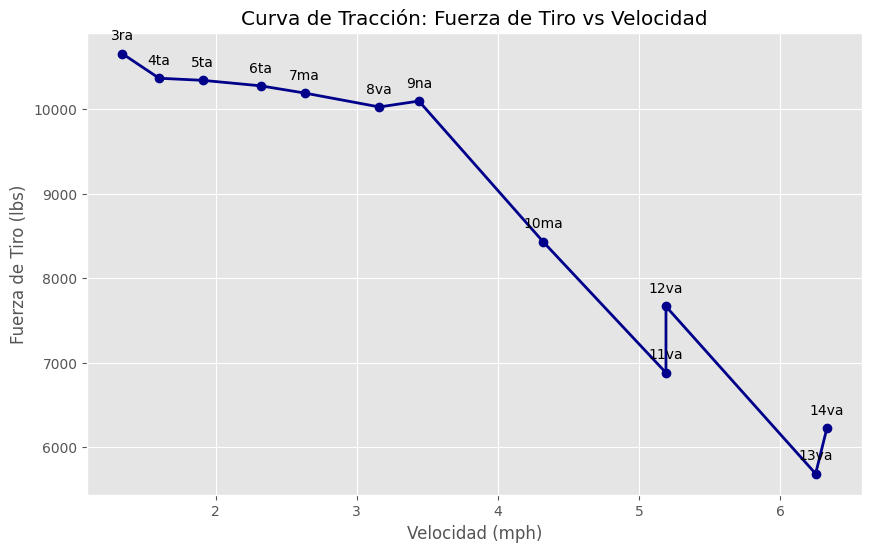

In [4]:
plt.figure(figsize=(10, 6))
plt.plot(df['Velocidad_mph'], df['Fuerza_Tiro_lbs'], marker='o', linestyle='-', color='darkblue', linewidth=2)
for i, txt in enumerate(df['Marcha']):
    plt.annotate(txt, (df['Velocidad_mph'][i], df['Fuerza_Tiro_lbs'][i]), textcoords="offset points", xytext=(0,10), ha='center')
plt.title('Curva de Tracción: Fuerza de Tiro vs Velocidad')
plt.xlabel('Velocidad (mph)')
plt.ylabel('Fuerza de Tiro (lbs)')
plt.grid(True)
plt.show()

## 4. Visualización: Patinaje (Slip) y Eficiencia

En el agro, un **patinaje (slip) entre 8% y 15%** se considera óptimo. Menos de 8% significa que el tractor está subutilizado (podría tirar más peso), y más de 15% significa que las llantas están patinando demasiado, destruyendo el suelo y desperdiciando combustible.

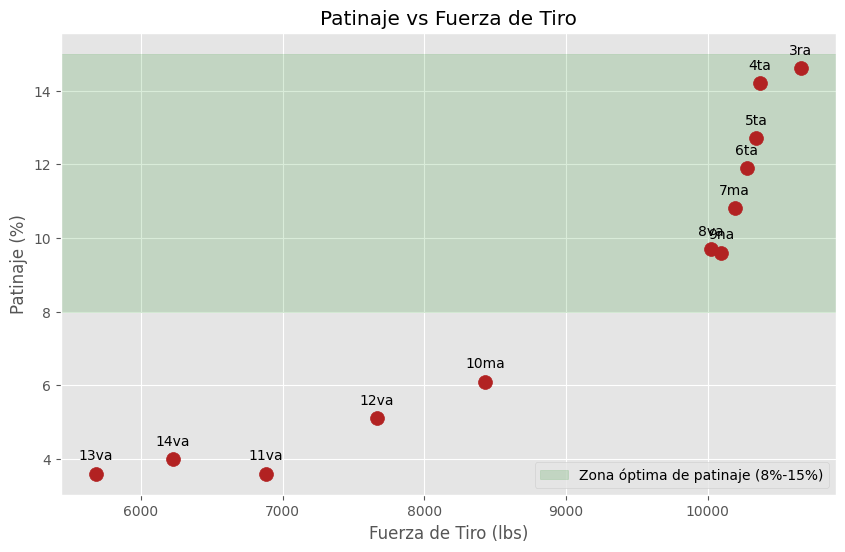

In [5]:
plt.figure(figsize=(10, 6))
plt.scatter(df['Fuerza_Tiro_lbs'], df['Patinaje_pct'], color='firebrick', s=100, zorder=3)
for i, txt in enumerate(df['Marcha']):
    plt.annotate(txt, (df['Fuerza_Tiro_lbs'][i], df['Patinaje_pct'][i]), textcoords="offset points", xytext=(0,10), ha='center')

# Zona óptima de patinaje (8% a 15%)
plt.axhspan(8, 15, color='green', alpha=0.15, label='Zona óptima de patinaje (8%-15%)')

plt.title('Patinaje vs Fuerza de Tiro')
plt.xlabel('Fuerza de Tiro (lbs)')
plt.ylabel('Patinaje (%)')
plt.legend()
plt.grid(True, zorder=0)
plt.show()

## 5. Consumo Específico de Combustible (SFC)

El SFC (lb/hp·hr) indica qué tan eficiente es el motor quemando combustible. Un valor más bajo es mejor. Nota cómo mejora drásticamente a medida que el tractor trabaja en marchas más altas (más carga de motor). El motor es más eficiente cuando trabaja cerca de su límite de potencia.

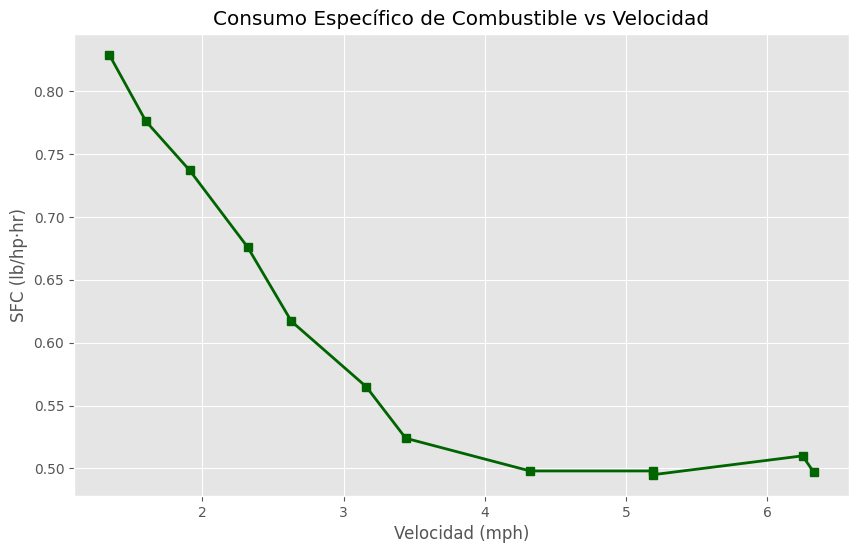

In [6]:
plt.figure(figsize=(10, 6))
plt.plot(df['Velocidad_mph'], df['SFC_lb_hp_hr'], marker='s', color='darkgreen', linewidth=2)
plt.title('Consumo Específico de Combustible vs Velocidad')
plt.xlabel('Velocidad (mph)')
plt.ylabel('SFC (lb/hp·hr)')
plt.grid(True)
plt.show()

## Conclusiones del Análisis

1. **Eficiencia Óptima:** Las marchas **12va, 13va y 14va** presentan la mayor eficiencia de tracción y el menor consumo específico de combustible. Sin embargo, su fuerza de tiro es menor. Son ideales para labores ligeras de alta velocidad (ej. rastreo, transporte).
2. **Trabajo Pesado:** Para labores que requieren mucha fuerza (arado), las marchas **6ta a 9na** son las ideales. Tienen un patinaje cercano al 10-12% (zona óptima) y mantienen una fuerza de tiro superior a las 10,000 lbs.
3. **La trampa de las marchas bajas:** Las marchas 3ra y 4ta generan mucha fuerza, pero su patinaje es del **14.6% y 14.2%**, acercándose al límite peligroso, y su consumo específico es el más alto (0.829 lb/hp·hr). Se usan solo para trabajos extremadamente pesados o cuando el terreno está muy blando.
4. **Costo Operativo:** Operar en la 3ra marcha cuesta aprox. $[tu cálculo] MXN/hr solo en diésel, mientras que en la 12va cuesta $[tu cálculo], pero realizando un trabajo diferente.